In [1]:
import os
from pathlib import Path

import pandas as pd
import tensorflow as tf
import random
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

SEED = 1729
VALIDATION_ROWS = 100
SPLIT_SEEDS = (101, 211, 307, 401, 503)
MODELS_PER_SPLIT = 4
param_names = ['tau_0', 'tau_rel', 'tau_th', 'eta_s', 'e_sw', 'Rgauss']

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Locate the repository data from the project root or a notebook directory.
REPO_ROOT = next((parent for parent in (Path.cwd(), *Path.cwd().parents)
                  if (parent / 'data').is_dir() and (parent / 'src').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Run this notebook from within the rhic-bes-ml-calibration repository.')
PION_PATH = REPO_ROOT / 'data'

def load_pion_data(directory, filename):
    csv_path = os.path.join(directory, filename)
    return pd.read_csv(csv_path, sep='\t', header=None)

spectra_raw = load_pion_data(PION_PATH, "ihkm_data_7-7_v6.txt")
complete_source_indices = spectra_raw.dropna().index.to_numpy(dtype=int)
spectra_all = spectra_raw.loc[complete_source_indices].reset_index(drop=True)

spectra_experiment = load_pion_data(PION_PATH, "exp_data_7-7_v3.txt")
errors_experiment = load_pion_data(PION_PATH, "err_data_7-7_v3.txt").squeeze()
cuts = load_pion_data(PION_PATH, "cuts_7-7_v3.txt").iloc[0].to_numpy(dtype=int)

pathY = os.path.join(PION_PATH, "7_7_ML_new_v4.csv")
dataY_raw = pd.read_csv(pathY, sep=',')
dataY = dataY_raw.loc[complete_source_indices, param_names].reset_index(drop=True)

assert len(spectra_all) == len(dataY)
assert len(spectra_all) - VALIDATION_ROWS == 1400
assert list(dataY.columns) == param_names

def parameter_key(row):
    return tuple(row[name] for name in param_names)

PARAMETER_GROUPS = {}
for row_index, row in dataY.iterrows():
    PARAMETER_GROUPS.setdefault(parameter_key(row), []).append(int(row_index))

def make_seeded_group_split(seed):
    """Select exactly VALIDATION_ROWS without splitting repeated parameter points."""
    rng = np.random.default_rng(seed)
    groups = list(PARAMETER_GROUPS.values())
    shuffled_groups = [groups[i] for i in rng.permutation(len(groups))]
    choices = {0: []}
    for group in shuffled_groups:
        group_size = len(group)
        for count, selected_groups in list(choices.items())[::-1]:
            new_count = count + group_size
            if new_count <= VALIDATION_ROWS and new_count not in choices:
                choices[new_count] = selected_groups + [group]
        if VALIDATION_ROWS in choices:
            break
    if VALIDATION_ROWS not in choices:
        raise RuntimeError(f"Seed {seed} cannot form exactly {VALIDATION_ROWS} validation rows")
    validation_indices = np.sort(np.asarray(
        [index for group in choices[VALIDATION_ROWS] for index in group], dtype=int
    ))
    validation_mask = np.zeros(len(dataY), dtype=bool)
    validation_mask[validation_indices] = True
    return np.flatnonzero(~validation_mask), validation_indices

def audit_split(split_seed, train_indices, validation_indices):
    assert len(validation_indices) == VALIDATION_ROWS
    assert len(train_indices) + len(validation_indices) == len(dataY)
    assert not np.intersect1d(train_indices, validation_indices).size
    assignments = {}
    for subset, indices in [('train', train_indices), ('validation', validation_indices)]:
        for _, row in dataY.iloc[indices].iterrows():
            assignments.setdefault(parameter_key(row), set()).add(subset)
    crossing = sum(len(subsets) > 1 for subsets in assignments.values())
    assert crossing == 0, f"Seed {split_seed}: {crossing} parameter groups cross the split"
    return dict(seed=split_seed, train_rows=len(train_indices),
                validation_rows=len(validation_indices),
                parameter_groups_crossing_split=crossing)

split_plans = {}
split_audit_rows = []
split_definition_dir = Path('artifacts') / Path('iHKMe_MCMC_7-7_v1.7.0') / 'split_definitions'
split_definition_dir.mkdir(parents=True, exist_ok=True)
for split_seed in SPLIT_SEEDS:
    train_indices, validation_indices = make_seeded_group_split(split_seed)
    split_plans[split_seed] = (train_indices, validation_indices)
    split_audit_rows.append(audit_split(split_seed, train_indices, validation_indices))
    np.savez_compressed(
        split_definition_dir / f'seed_{split_seed}.npz',
        train_indices=train_indices,
        validation_indices=validation_indices,
        train_source_indices=complete_source_indices[train_indices],
        validation_source_indices=complete_source_indices[validation_indices],
    )

split_audit = pd.DataFrame(split_audit_rows)
display(split_audit)
print(spectra_experiment)
print(errors_experiment)
print(cuts)


2026-09-27 21:54:07.790528: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-27 21:54:07.800606: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1790535247.812388 3856633 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1790535247.815865 3856633 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-27 21:54:07.828087: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

,seed,train_rows,validation_rows,parameter_groups_crossing_split
0,101,1400,100,0
1,211,1400,100,0
2,307,1400,100,0
3,401,1400,100,0
4,503,1400,100,0


       0        1        2        3        4        5       6       7    \
0  49.9923  36.5845  26.9058  19.9091  14.8345  11.1741  8.3885  6.3395   

      8       9    ...      144      145      146      147      148      149  \
0  4.6846  3.7024  ...  3.74217  3.47308  3.79047  3.50191  3.21622  3.07176   

       150      151      152     153  
0  4.16821  3.51568  2.93381  2.4676  

[1 rows x 154 columns]
0      3.434000
1      2.448000
2      1.771000
3      1.297000
4      0.960000
         ...   
149    0.040859
150    0.042385
151    0.061378
152    0.052756
153    0.048735
Name: 0, Length: 154, dtype: float64
[ 23  46  69  92 118 134 142 146 150 154]


In [2]:
n_spec = int(cuts[5])
n_obs = int(cuts[6])

def transform_observables(frame):
    spectra = frame.iloc[:, :n_spec].to_numpy(dtype=float)
    rest = frame.iloc[:, n_spec:n_obs].to_numpy(dtype=float)
    if not np.all(spectra > 0):
        raise ValueError("All spectrum values must be positive before the log transform")
    return np.concatenate([np.log(spectra), rest], axis=1)

X_all_transformed = transform_observables(spectra_all)
X_experiment_transformed = transform_observables(spectra_experiment)

def prepare_split(train_indices, validation_indices):
    Y_train = dataY.iloc[train_indices].reset_index(drop=True)
    Y_valid = dataY.iloc[validation_indices].reset_index(drop=True)
    X_train = X_all_transformed[train_indices]
    X_valid = X_all_transformed[validation_indices]

    scalerX = StandardScaler().fit(X_train)
    scalerY = StandardScaler().fit(Y_train[param_names].to_numpy(dtype=float))
    return dict(
        train_indices=train_indices,
        validation_indices=validation_indices,
        Y_train=Y_train,
        Y_valid=Y_valid,
        X_train=X_train,
        X_valid=X_valid,
        X_train_norm=scalerX.transform(X_train),
        X_valid_norm=scalerX.transform(X_valid),
        Y_train_norm=scalerY.transform(Y_train[param_names].to_numpy(dtype=float)),
        Y_valid_norm=scalerY.transform(Y_valid[param_names].to_numpy(dtype=float)),
        scalerX=scalerX,
        scalerY=scalerY,
    )

prepared_splits = {
    seed: prepare_split(*split_plans[seed]) for seed in SPLIT_SEEDS
}

# Keep the first split as the common normalized coordinate system used by the
# likelihood and by the existing diagnostic/plotting cells. Each model still
# trains with scalers fitted only on its own split's training rows.
reference_split = prepared_splits[SPLIT_SEEDS[0]]
scalerX = reference_split['scalerX']
scalerY = reference_split['scalerY']
Y_train = reference_split['Y_train']
Y_valid = reference_split['Y_valid']
X_train = reference_split['X_train']
X_valid = reference_split['X_valid']
X_train_norm = reference_split['X_train_norm']
X_valid_norm = reference_split['X_valid_norm']
Y_train_norm = reference_split['Y_train_norm']
Y_valid_norm = reference_split['Y_valid_norm']
spectra_train = spectra_all.iloc[reference_split['train_indices']].reset_index(drop=True)
spectra_validation = spectra_all.iloc[reference_split['validation_indices']].reset_index(drop=True)
X_experiment = X_experiment_transformed
X_experiment_norm = scalerX.transform(X_experiment)
Y_train.head()


,tau_0,tau_rel,tau_th,eta_s,e_sw,Rgauss
0,3.90,3.3,8.15,0.34,0.41,0.75
1,3.40,2.5,7.40,0.21,0.36,1.39
2,2.70,4.0,8.10,0.19,0.37,1.36
3,2.35,3.2,7.20,0.39,0.39,0.78
4,3.00,3.8,8.85,0.38,0.45,0.72


In [3]:
X_train_spectra = spectra_train.iloc[:, :n_spec]
X_train_spectra.head()


,0,1,2,3,4,5,6,7,8,9,...,124,125,126,127,128,129,130,131,132,133
0,54.0255,40.9402,26.1341,17.0048,13.8692,8.83948,6.85054,6.80114,3.95822,2.81218,...,0.040429,0.023593,0.019291,0.048815,0.032011,0.017366,0.017707,0.011075,0.009704,0.006084
1,54.1431,43.0695,26.7113,20.4902,14.7932,10.68560,7.89361,5.98854,5.02201,3.16910,...,0.045999,0.028804,0.033865,0.058691,0.037401,0.031031,0.026508,0.015889,0.009675,0.010591
2,58.5054,43.5067,28.1981,22.5707,15.0477,11.30870,8.10974,5.93084,5.33667,3.26130,...,0.051692,0.026853,0.031959,0.049283,0.039272,0.028263,0.017285,0.016447,0.010771,0.008268
3,56.5626,36.6584,27.6727,19.6769,14.5154,10.73440,7.95781,5.92965,4.40688,3.59218,...,0.054931,0.058723,0.039664,0.053185,0.056827,0.034390,0.028123,0.028854,0.038409,0.015283
4,54.3627,36.8779,27.7583,19.6401,13.3448,10.44260,8.03201,5.34968,5.20442,3.14131,...,0.044893,0.034730,0.025468,0.042180,0.039811,0.023741,0.019499,0.012777,0.015648,0.010746


In [4]:
X_valid_spectra = spectra_validation.iloc[:, :n_spec]
X_valid_spectra.head()


,0,1,2,3,4,5,6,7,8,9,...,124,125,126,127,128,129,130,131,132,133
0,56.9718,39.1953,28.1604,21.3010,14.8463,10.07000,8.26966,6.21243,4.51513,3.41757,...,0.036465,0.044078,0.027046,0.053115,0.040272,0.026205,0.057818,0.016213,0.009428,0.012829
1,71.8682,53.1774,37.2316,27.7597,20.5297,15.18930,11.71400,8.91061,6.90630,5.24745,...,0.059309,0.039058,0.044577,0.048821,0.049184,0.041858,0.030281,0.026896,0.025134,0.018885
2,53.9299,38.2293,27.0629,18.1146,13.6159,9.92863,7.12739,6.50887,4.53291,3.07548,...,0.040393,0.029579,0.020738,0.042207,0.034986,0.019209,0.015912,0.014818,0.007134,0.006908
3,57.4685,41.2954,29.2966,21.4691,16.0632,12.08690,9.06218,7.22898,5.40026,4.11430,...,0.046440,0.050622,0.043684,0.054123,0.048531,0.040009,0.030694,0.027732,0.021610,0.015389
4,50.7647,34.8249,25.1971,17.1922,13.0819,9.02377,6.47980,5.07319,3.79506,2.94081,...,0.050849,0.041091,0.040510,0.054303,0.045970,0.034726,0.022565,0.019496,0.009650,0.007239


In [5]:
X_experiment_spectra = spectra_experiment.iloc[:, :n_spec]
X_experiment_spectra.head()


,0,1,2,3,4,5,6,7,8,9,...,124,125,126,127,128,129,130,131,132,133
0,49.9923,36.5845,26.9058,19.9091,14.8345,11.1741,8.3885,6.3395,4.6846,3.7024,...,0.0404,0.0361,0.0326,0.0484,0.0378,0.0295,0.0245,0.0175,0.0115,0.0089


In [6]:
# All observable transformations and split-specific scaler fits are performed
# in prepare_split above. The first split is exposed here only for diagnostics.
print(X_experiment)


[[ 3.91186899  3.59962465  3.29234188  2.99117691  2.69695555  2.4135986
   2.12686172  1.8467999   1.54428053  1.30898126  2.84824683  2.2774929
   1.72124759  1.19755224  0.69194646  0.18265483 -0.32351653 -0.84327264
  -1.31938366 -1.78916284 -2.27302629 -2.74264165 -3.29144652  3.80427074
   3.50338086  3.21384318  2.91817606  2.63920018  2.3497549   2.08600744
   1.80235316  1.52781562  1.27982212  2.78574554  2.23012192  1.6818888
   1.17164587  0.67228099  0.16712331 -0.32434606 -0.83309914 -1.32200587
  -1.81769285 -2.25856821 -2.70755033 -3.30497852  0.993511    0.86550257
   0.71969174  0.56950954  0.36630839  0.16211885 -0.03541995 -0.1909184
  -0.45460283 -0.70259164  0.467939    0.06090693 -0.32351653 -0.81441127
  -1.24029107 -1.68147112 -2.14900601 -2.67800608 -3.04913305 -3.58993951
  -4.19306054 -4.63562939 -5.24004846  1.89784472  1.78236548  1.6496197
   1.49330851  1.32359415  1.15744707  0.99879195  0.82452626  0.57711885
   0.36401792  1.39314584  1.0551131   0.66

In [7]:
# Parameter scaling is also split-specific; these arrays correspond to the
# first split and remain available to the existing diagnostic cells.
Y_valid_norm[:5]


array([[-0.5125732 , -0.46947887, -0.12625824, -1.69125187, -0.87137667,
         0.14692806],
       [-1.25160769, -1.70480444, -1.84786987, -0.16781161, -0.70075746,
         1.35211327],
       [ 0.88338082, -0.77831026, -0.43671279, -0.92953174, -0.70075746,
         1.56732491],
       [-1.16949274, -1.24155735, -1.45274589,  1.68208014,  0.32295779,
        -1.31651111],
       [ 0.71915094, -0.93272596,  0.04308061, -1.58243471,  0.83481541,
        -0.88608783]])

In [8]:
model_bundles = []
models_by_split = {seed: [] for seed in SPLIT_SEEDS}

for split_offset, split_seed in enumerate(SPLIT_SEEDS):
    split = prepared_splits[split_seed]
    for member_index in range(MODELS_PER_SPLIT):
        member_seed = SEED + 1000 * split_offset + member_index
        tf.keras.utils.set_random_seed(member_seed)
        model = keras.models.Sequential([
            keras.layers.Input(shape=(len(param_names),)),
            keras.layers.Dense(64, activation="swish"),
            keras.layers.Dense(128, activation="swish"),
            keras.layers.Dense(128, activation="swish"),
            keras.layers.Dense(n_obs, activation="linear")
        ])
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="mse",
            metrics=["mse"]
        )
        print(f"Fit split {split_seed}, member {member_index}, seed {member_seed}")
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=100,
            restore_best_weights=True
        )
        history = model.fit(
            split['Y_train_norm'],
            split['X_train_norm'],
            batch_size=64,
            epochs=3000,
            verbose=0,
            validation_data=(split['Y_valid_norm'], split['X_valid_norm']),
            callbacks=[early_stop]
        )
        bundle = dict(
            model=model,
            split_seed=split_seed,
            member_seed=member_seed,
            scalerX=split['scalerX'],
            scalerY=split['scalerY'],
        )
        model_bundles.append(bundle)
        models_by_split[split_seed].append(bundle)

assert len(model_bundles) == len(SPLIT_SEEDS) * MODELS_PER_SPLIT == 20
models = [bundle['model'] for bundle in model_bundles]
print("finished: 20 models across 5 validation splits")


2026-09-27 21:54:09.776334: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error


Fit split 101, member 0, seed 1729
Fit split 101, member 1, seed 1730
Fit split 101, member 2, seed 1731
Fit split 101, member 3, seed 1732
Fit split 211, member 0, seed 2729
Fit split 211, member 1, seed 2730
Fit split 211, member 2, seed 2731
Fit split 211, member 3, seed 2732
Fit split 307, member 0, seed 3729
Fit split 307, member 1, seed 3730
Fit split 307, member 2, seed 3731
Fit split 307, member 3, seed 3732
Fit split 401, member 0, seed 4729
Fit split 401, member 1, seed 4730
Fit split 401, member 2, seed 4731
Fit split 401, member 3, seed 4732
Fit split 503, member 0, seed 5729
Fit split 503, member 1, seed 5730
Fit split 503, member 2, seed 5731
Fit split 503, member 3, seed 5732
finished: 20 models across 5 validation splits


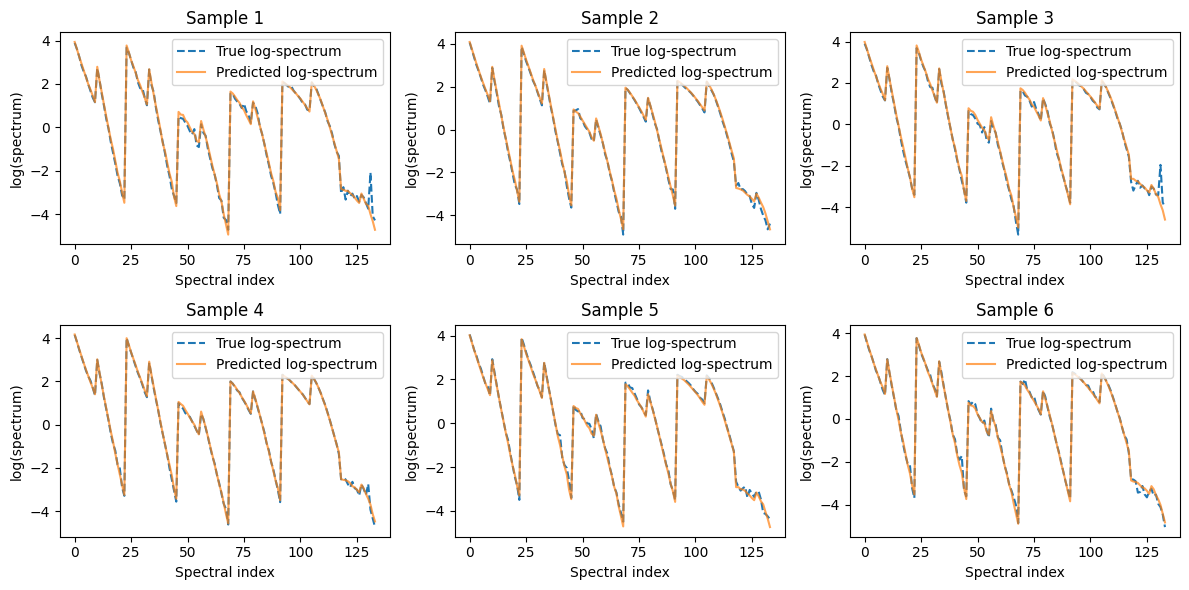

In [9]:
import random
import matplotlib.pyplot as plt

# Show one member from the reference split in transformed-observable space.
reference_bundle = models_by_split[SPLIT_SEEDS[0]][0]
model = reference_bundle['model']
X_valid_pred = reference_bundle['scalerX'].inverse_transform(
    model.predict(Y_valid_norm, verbose=0)
)

num_samples = 6
indices = random.Random(SEED).sample(range(len(Y_valid)), num_samples)

plt.figure(figsize=(12, 6))
for i, idx in enumerate(indices):
    plt.subplot(2, 3, i + 1)
    plt.plot(X_valid[idx][:n_spec], label="True log-spectrum", linestyle='dashed')
    plt.plot(X_valid_pred[idx][:n_spec], label="Predicted log-spectrum", alpha=0.7)
    plt.xlabel("Spectral index")
    plt.ylabel("log(spectrum)")
    plt.title(f"Sample {i+1}")
    plt.legend()
plt.tight_layout()
plt.show()


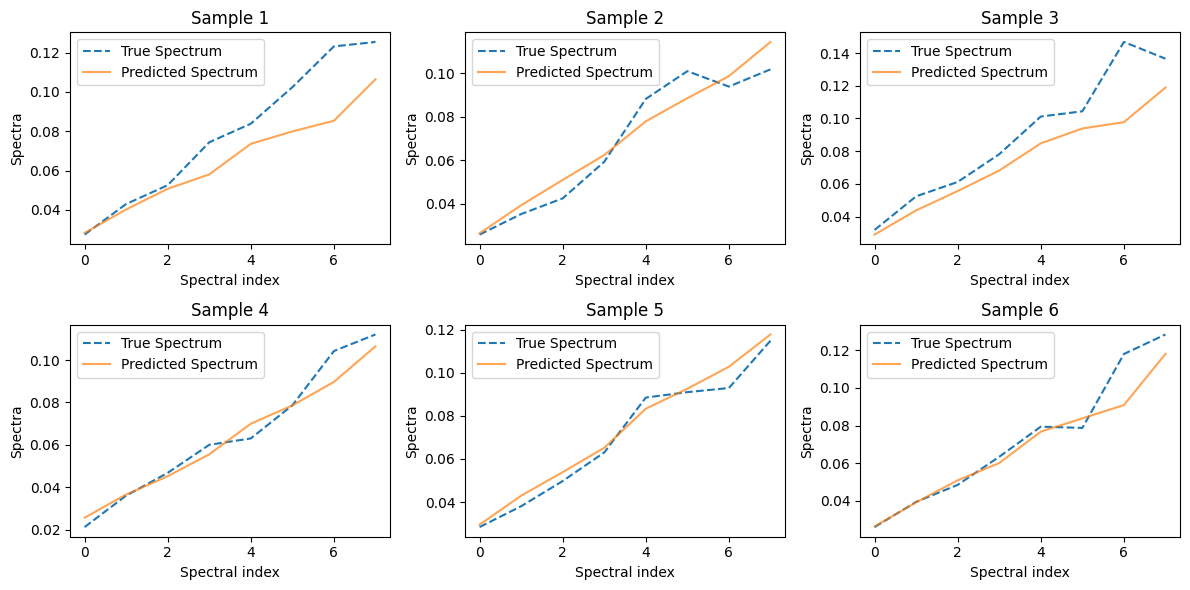

In [10]:


plt.figure(figsize=(12, 6))
for i, idx in enumerate(indices):
    v2_valid = X_valid[idx][cuts[5]:]
    v2_pred = X_valid_pred[idx][cuts[5]:]
    plt.subplot(2, 3, i + 1)
    plt.plot(v2_valid, label="True Spectrum", linestyle='dashed')
    plt.plot(v2_pred, label="Predicted Spectrum", alpha=0.7)
    plt.xlabel("Spectral index")
    plt.ylabel("Spectra")
    plt.title(f"Sample {i+1}")
    plt.legend()
plt.tight_layout()
plt.show()

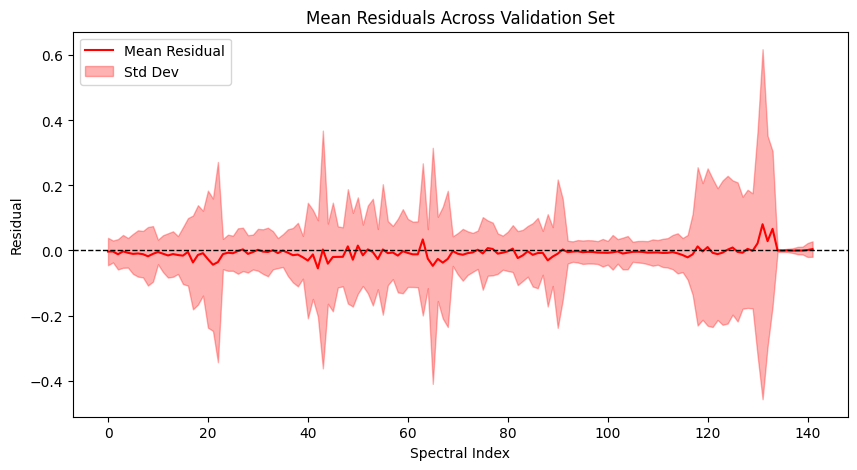

In [11]:
residuals = X_valid - X_valid_pred
plt.figure(figsize=(10, 5))
plt.plot(np.mean(residuals, axis=0), label="Mean Residual", color='red')
plt.fill_between(range(cuts[6]), 
                 np.mean(residuals, axis=0) - np.std(residuals, axis=0),
                 np.mean(residuals, axis=0) + np.std(residuals, axis=0),
                 color='red', alpha=0.3, label="Std Dev")
plt.axhline(0, linestyle='dashed', color='black', linewidth=1)
plt.xlabel("Spectral Index")
plt.ylabel("Residual")
plt.title("Mean Residuals Across Validation Set")
plt.legend()
plt.show()

In [12]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# pip install emcee corner
import emcee
import corner

# ============================================================
# 1. Parameter names and split-independent design-domain bounds
# ============================================================

ndim = len(param_names)
prior_min = dataY[param_names].min().to_numpy(dtype=float)
prior_max = dataY[param_names].max().to_numpy(dtype=float)


In [13]:
# ============================================================
# 2. Experimental target in the common likelihood coordinates
# ============================================================
# Predictions from every split are mapped into the reference split's
# normalized log-spectrum/native-v2 coordinates before ensemble aggregation.

X_exp_transformed = X_experiment_transformed
X_exp_norm_all = scalerX.transform(X_exp_transformed)
X_exp_norm = X_exp_norm_all[0]
X_exp_spectra = spectra_experiment.iloc[:, :n_spec].to_numpy(dtype=float)
X_exp_rest = spectra_experiment.iloc[:, n_spec:n_obs].to_numpy(dtype=float)


In [14]:
# ============================================================
# 3. Transform experimental one-sigma errors into normalized space
# ============================================================
# IMPORTANT:
# errors_experiment is assumed to be in ORIGINAL observable space:
#   - first 122 bins: sigma of raw spectra x
#   - remaining bins: sigma of raw remaining observables
#
# Since training used log(x) for the first 122 bins, propagate:
#   sigma_log(x) ≈ sigma_x / x
#
# Then divide by scalerX.scale_ to get sigma in normalized space.

errors_experiment = np.asarray(errors_experiment[:cuts[6]], dtype=float)

if errors_experiment.shape != (cuts[6],):
    raise ValueError(f"errors_experiment must have shape ({cuts[6]},), got {errors_experiment.shape}")

# Use the same experimental row chosen above
if X_exp_spectra.shape[0] == 1:
    x_spec_row = X_exp_spectra[0]
    x_rest_row = X_exp_rest[0]
else:
    x_spec_row = X_exp_spectra[0]
    x_rest_row = X_exp_rest[0]

# Protect against division by zero in spectra
safe_spec = np.maximum(x_spec_row, 1e-12)

sigma_transformed = np.zeros(n_obs, dtype=float)

sigma_transformed[:n_spec] = errors_experiment[:n_spec] / np.maximum(x_spec_row, 1e-12)
sigma_transformed[n_spec:n_obs] = errors_experiment[n_spec:n_obs]

sigma_exp_norm = sigma_transformed / scalerX.scale_[:n_obs]
sigma_exp_norm = np.maximum(sigma_exp_norm, 1e-12)

In [15]:
# ============================================================
# 4. Estimate generalization error from split-ensemble validation residuals
#    in the common likelihood coordinates
# ============================================================

split_mean_residuals = []
for split_seed in SPLIT_SEEDS:
    split = prepared_splits[split_seed]
    member_predictions_common = []
    for bundle in models_by_split[split_seed]:
        prediction_private_norm = bundle['model'].predict(
            split['Y_valid_norm'], verbose=0
        )
        prediction_transformed = bundle['scalerX'].inverse_transform(
            prediction_private_norm
        )
        member_predictions_common.append(scalerX.transform(prediction_transformed))
    split_prediction_mean = np.mean(member_predictions_common, axis=0)
    validation_truth_common = scalerX.transform(split['X_valid'])
    split_mean_residuals.append(validation_truth_common - split_prediction_mean)

residuals_valid_norm = np.concatenate(split_mean_residuals, axis=0)
sigma_emu_norm = np.std(residuals_valid_norm, axis=0, ddof=1)
sigma_emu_norm = np.maximum(sigma_emu_norm, 1e-12)

sigma_tot_norm = np.sqrt(sigma_exp_norm**2 + sigma_emu_norm**2)
inv_var = 1.0 / (sigma_tot_norm ** 2)


In [16]:
X_design_norm = scalerX.transform(X_all_transformed)
chi2_design = np.sum(((X_design_norm - X_exp_norm) / sigma_tot_norm) ** 2, axis=1)

best_idx = np.argmin(chi2_design)

print("Best existing design point chi2:", chi2_design[best_idx])
print("Best existing design point chi2/Nobs:", chi2_design[best_idx] / len(X_exp_norm))
print("Best existing parameters:")
print(dataY.iloc[best_idx])


Best existing design point chi2: 106.14114243525337
Best existing design point chi2/Nobs: 0.7474728340510801
Best existing parameters:
tau_0      2.15
tau_rel    4.30
tau_th     7.90
eta_s      0.26
e_sw       0.38
Rgauss     1.06
Name: 1117, dtype: float64


In [17]:
# ============================================================
# 5. Twenty-member emulator prediction helper
# ============================================================

def predict_x_norm(theta):
    """Return mean/std of all 20 predictions in common likelihood coordinates."""
    theta = np.asarray(theta, dtype=float)
    predictions_common = []
    for bundle in model_bundles:
        theta_private_norm = bundle['scalerY'].transform(theta.reshape(1, -1))
        prediction_private_norm = bundle['model'](
            theta_private_norm, training=False
        ).numpy()
        prediction_transformed = bundle['scalerX'].inverse_transform(
            prediction_private_norm
        )
        predictions_common.append(scalerX.transform(prediction_transformed)[0])

    predictions_common = np.asarray(predictions_common)
    pred_mean = predictions_common.mean(axis=0)
    pred_std = predictions_common.std(axis=0, ddof=1)
    return pred_mean, pred_std


In [18]:
# ============================================================
# 6. Log-prior, log-likelihood, log-posterior
# ============================================================

weights = np.ones(n_obs)
weights[:n_spec] *= 1.0 / n_spec
weights[n_spec:n_obs] *= 1.0 / (n_obs - n_spec)

def log_prior(theta):
    theta = np.asarray(theta, dtype=float)
    # Individual parameter bounds
    if np.any(theta < prior_min) or np.any(theta > prior_max):
        return -np.inf

    tau_0, tau_rel, tau_th = theta[:3]

    # Physical constraints: tau_0 + tau_rel <= tau_th < tau_0 + 3 * tau_rel
    if tau_0 + tau_rel > tau_th or tau_0 + 3 * tau_rel <= tau_th:
        return -np.inf

    return 0.0

def log_likelihood(theta):
    x_pred_norm, sigma_emu_ens_norm = predict_x_norm(theta)

    diff = X_exp_norm - x_pred_norm

    sigma_tot_norm = np.sqrt(
        sigma_exp_norm**2 +
        sigma_emu_norm**2 +
        sigma_emu_ens_norm**2
    )

    inv_var = 1.0 / np.maximum(sigma_tot_norm**2, 1e-12)

    chi2 = np.sum(diff**2 * inv_var)

    log_det = np.sum(np.log(2.0 * np.pi * sigma_tot_norm**2))

    return -0.5 * (chi2 + log_det)

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


In [19]:
# ============================================================
# 7. Initialize walkers
# ============================================================
from enum import Enum

rng = np.random.default_rng(42)
class RunMode(Enum):
    PROD = "prod"
    STABLE = "stable"
    TEST = "test"


MODE = RunMode.STABLE


if MODE == RunMode.TEST:
    nwalkers = 24
    nsteps = 1000
    burnin = 200
    thin = 5

elif MODE == RunMode.STABLE:
    nwalkers = 32
    nsteps = 5000
    burnin = 1000
    thin = 10

elif MODE == RunMode.PROD:
    nwalkers = 48
    nsteps = 20000
    burnin = 5000
    thin = 20

else:
    raise ValueError(f"Unknown run mode: {MODE}")

# Uniform initialization inside prior box
def sample_valid_initial_position():
    while True:
        theta = rng.uniform(low=prior_min, high=prior_max)

        tau_0, tau_rel, tau_th = theta[:3]

        if tau_0 + tau_rel <= tau_th and tau_0 + 3 * tau_rel > tau_th:
            return theta


p0 = np.array([
    sample_valid_initial_position()
    for _ in range(nwalkers)
])

In [20]:
# ============================================================
# 8. Run MCMC
# ============================================================

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)

print("Running MCMC...")
sampler.run_mcmc(p0, nsteps, progress=True)

Running MCMC...


100%|█████████████████████████████████████| 5000/5000 [2:08:30<00:00,  1.54s/it]


State([[ 2.07447816  5.14801577  7.34302539  0.30685249  0.36544221  1.10055092]
 [ 2.32496958  3.36915997  7.15099725  0.22158698  0.42633591  0.94882985]
 [ 2.31171125  4.46781938  7.5274606   0.29348029  0.33656459  1.23560263]
 [ 2.53605864  2.40071808  9.68254137  0.26631529  0.43260286  1.03491813]
 [ 2.10110541  5.13002252  9.24023972  0.33701517  0.36928835  1.11461733]
 [ 2.01380103  4.22537955  6.31306709  0.11882403  0.38942476  0.97190677]
 [ 2.11950303  4.68084021  7.40975412  0.18278499  0.32785644  1.15013097]
 [ 2.37943116  3.0114255  10.13295096  0.26517549  0.40044267  0.97752363]
 [ 2.3967548   3.24422742 10.64096772  0.22800688  0.39987418  1.0689967 ]
 [ 2.35468723  3.76720258  7.14456228  0.17355956  0.40038297  1.08385662]
 [ 1.91815436  4.97312363  9.20178478  0.2992583   0.43584147  0.80835677]
 [ 2.34919447  3.29235928 11.52712421  0.32758817  0.41932092  1.0157967 ]
 [ 2.18286756  4.34463225  9.23709067  0.38228484  0.42061041  1.00481527]
 [ 1.9106654   5.59

In [21]:
# ============================================================
# 9. Collect posterior samples
# ============================================================

samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)
log_probs = sampler.get_log_prob(discard=burnin, thin=thin, flat=True)

print("Posterior sample shape:", samples.shape)

# MAP estimate
map_idx = np.argmax(log_probs)
theta_map = samples[map_idx]

print("\nMAP estimate:")
for name, value in zip(param_names, theta_map):
    print(f"{name:8s} = {value:.6g}")

# Median and central 68% interval
q16, q50, q84 = np.percentile(samples, [16, 50, 84], axis=0)

print("\nPosterior summary:")
for i, name in enumerate(param_names):
    minus = q50[i] - q16[i]
    plus = q84[i] - q50[i]
    print(f"{name:8s} = {q50[i]:.6g}  -{minus:.3g} / +{plus:.3g}")

Posterior sample shape: (12800, 6)

MAP estimate:
tau_0    = 2.37211
tau_rel  = 3.26266
tau_th   = 10.6306
eta_s    = 0.334662
e_sw     = 0.404653
Rgauss   = 1.00601

Posterior summary:
tau_0    = 2.21972  -0.219 / +0.232
tau_rel  = 3.98098  -0.819 / +0.937
tau_th   = 9.38251  -1.57 / +1.45
eta_s    = 0.288582  -0.0716 / +0.0683
e_sw     = 0.391765  -0.0376 / +0.0405
Rgauss   = 1.00659  -0.117 / +0.126


In [22]:
# ============================================================
# 10. Acceptance fraction and rough autocorrelation check
# ============================================================

acceptance = np.mean(sampler.acceptance_fraction)
print(f"\nMean acceptance fraction: {acceptance:.3f}")

try:
    tau_int = sampler.get_autocorr_time()
    print("Integrated autocorrelation time:")
    for name, tau in zip(param_names, tau_int):
        print(f"{name:8s}: {tau:.2f}")
except Exception as e:
    print("Autocorrelation time not reliable yet:", str(e))


Mean acceptance fraction: 0.435
Integrated autocorrelation time:
tau_0   : 96.80
tau_rel : 98.39
tau_th  : 87.75
eta_s   : 93.13
e_sw    : 86.49
Rgauss  : 85.81


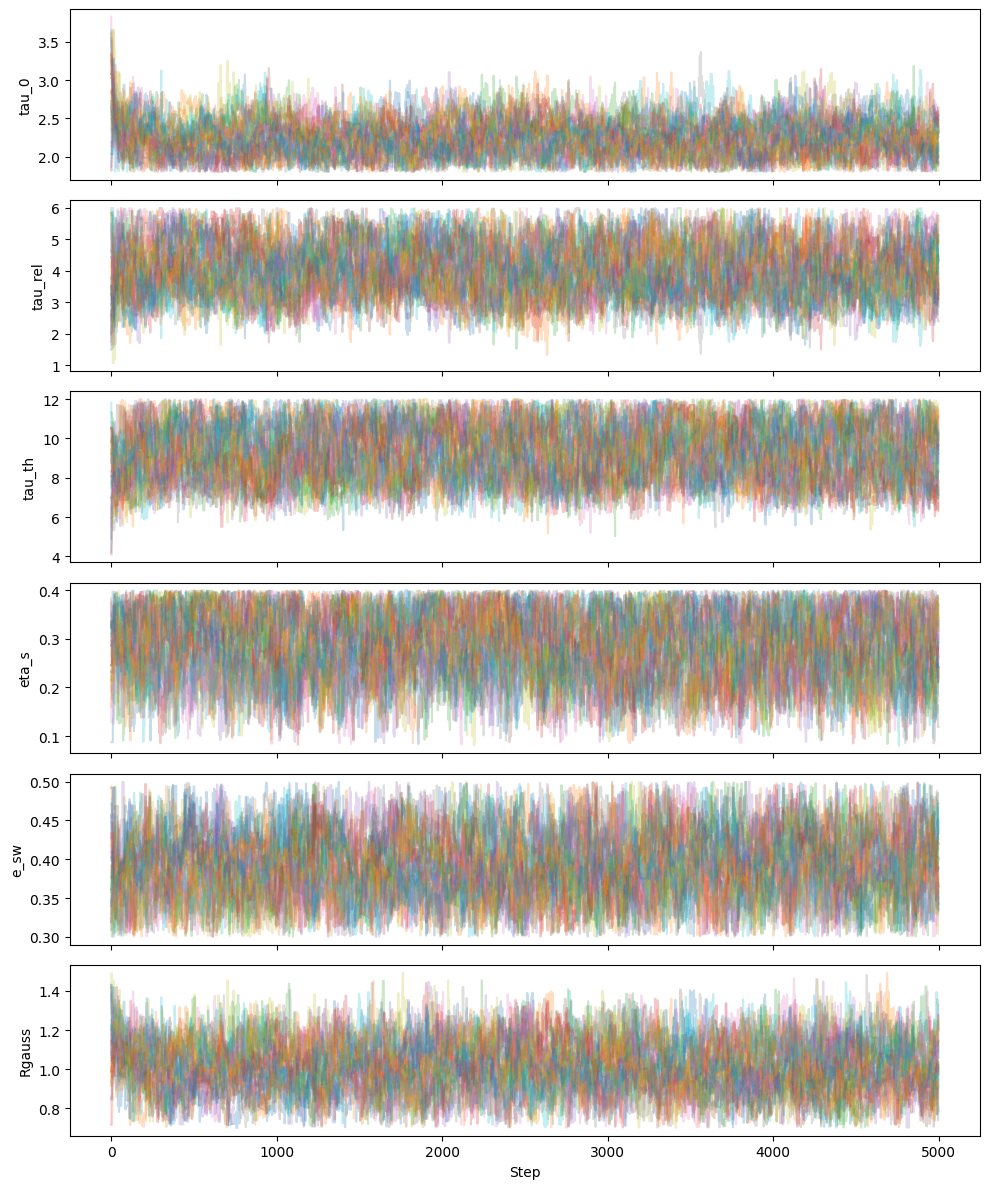

In [23]:
# ============================================================
# 11. Trace plots
# ============================================================

chain = sampler.get_chain()

fig, axes = plt.subplots(ndim, 1, figsize=(10, 2.0 * ndim), sharex=True)
for i in range(ndim):
    axes[i].plot(chain[:, :, i], alpha=0.25)
    axes[i].set_ylabel(param_names[i])
axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

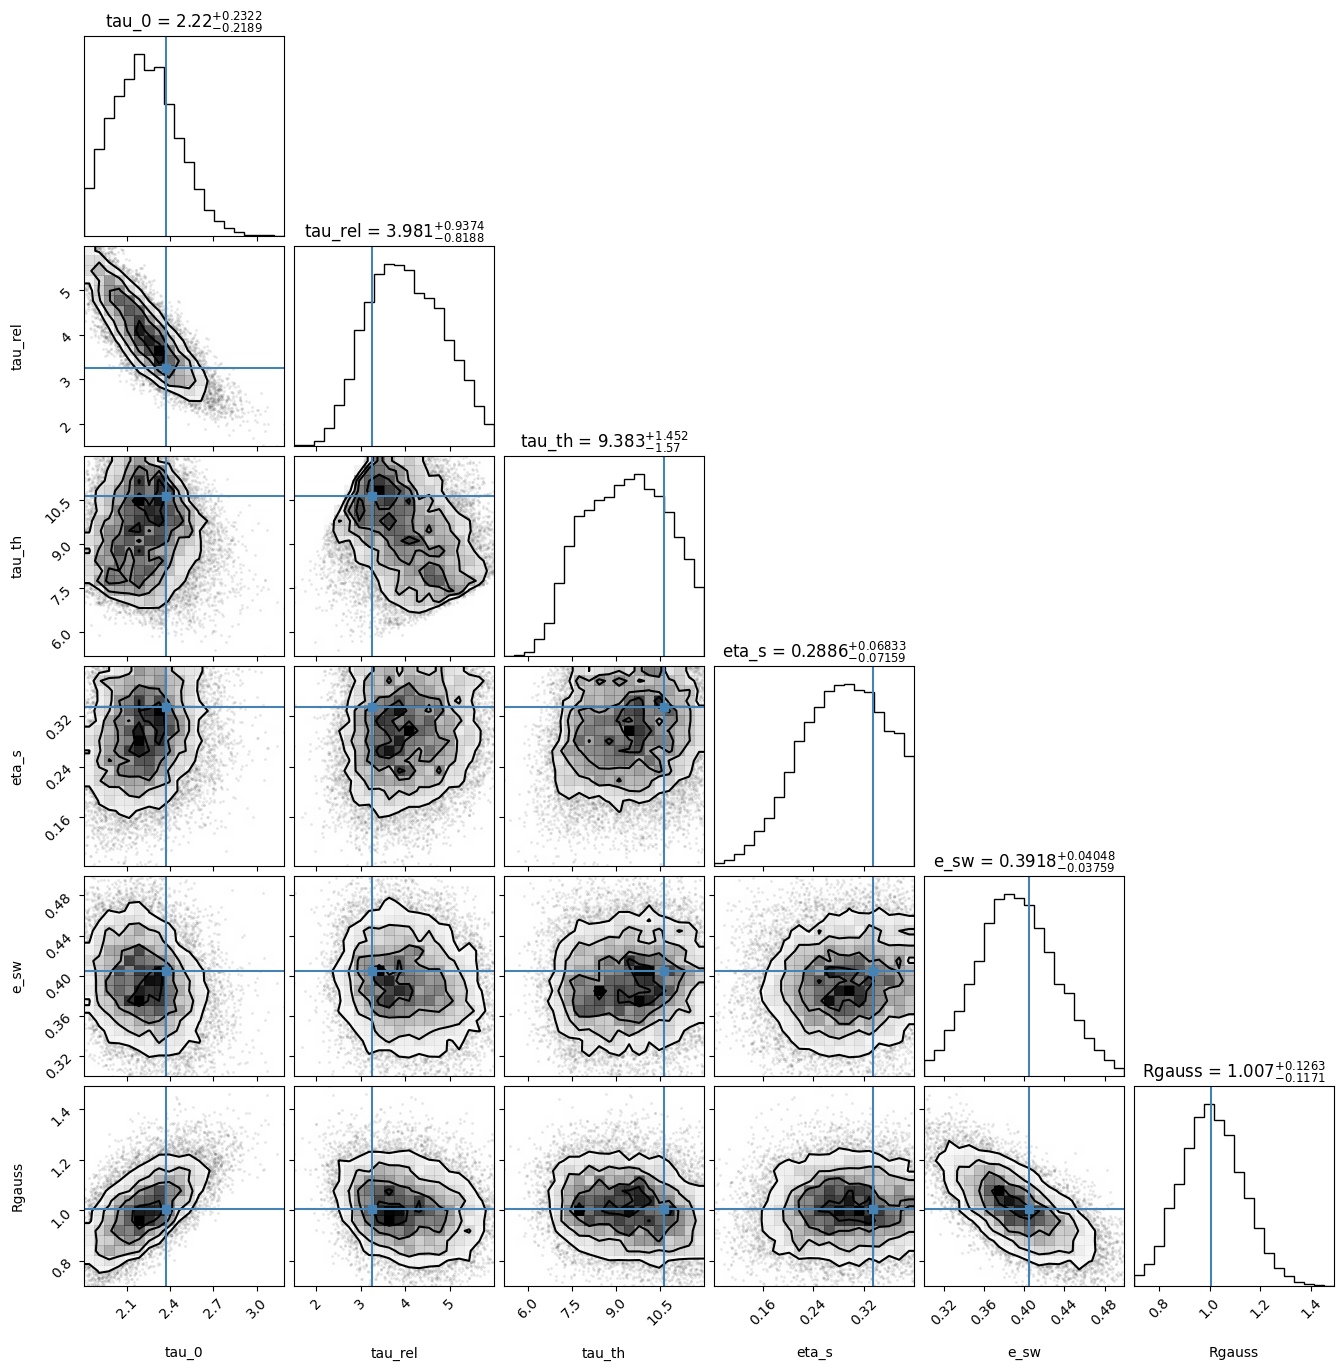

In [24]:
# ============================================================
# 12. Corner plot
# ============================================================

fig = corner.corner(
    samples,
    labels=param_names,
    truths=theta_map,
    show_titles=True,
    title_fmt=".4g"
)
plt.show()

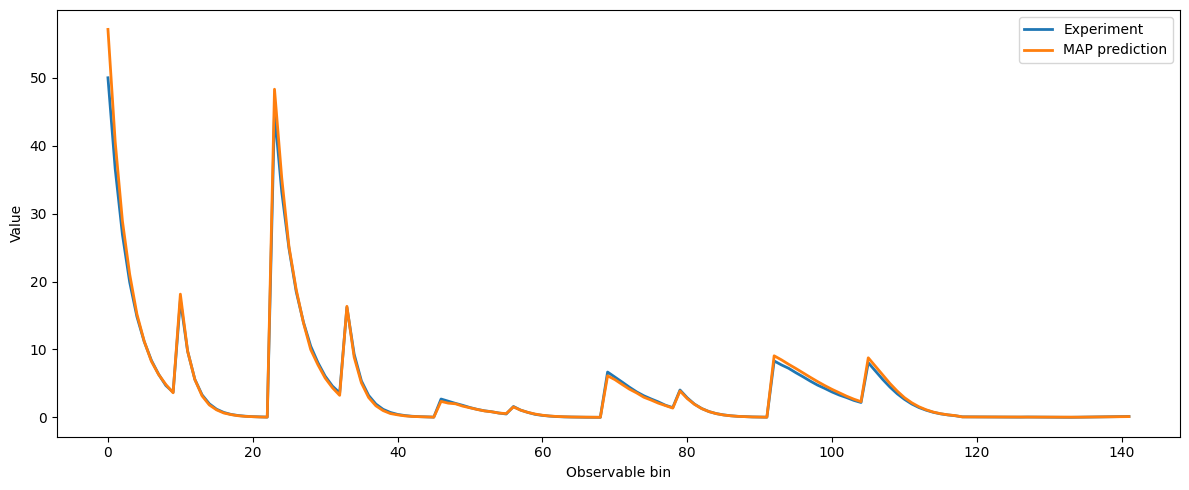

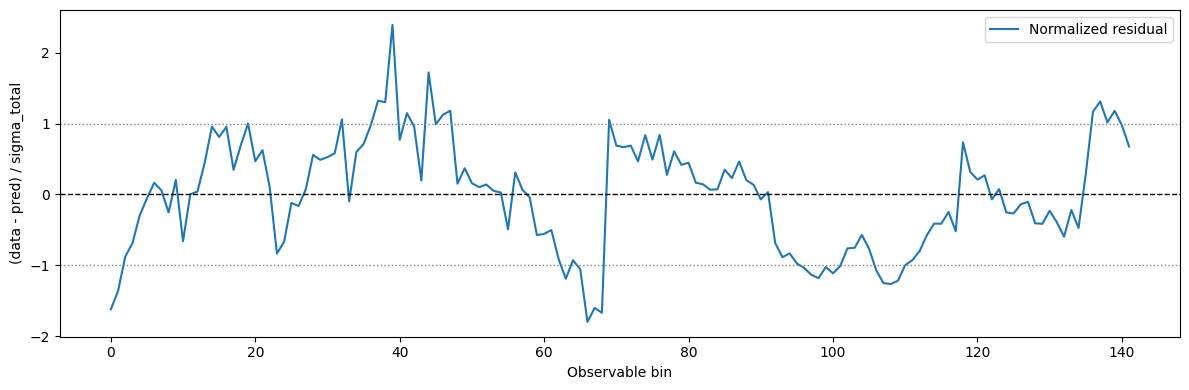


MAP chi2: 85.677
MAP chi2 / Nbins: 0.603


In [25]:
# ============================================================
# 13. Posterior predictive comparison
# ============================================================

x_map_pred_norm, sigma_emu_ens_norm_map = predict_x_norm(theta_map)

# Convert normalized predictions back to transformed physical target space:
# first 122 bins are log(spectra), last bins are unchanged observables
x_map_pred_transformed = scalerX.inverse_transform(x_map_pred_norm.reshape(1, -1))[0]
x_exp_transformed = scalerX.inverse_transform(X_exp_norm.reshape(1, -1))[0]

# Optional: convert first 122 bins back from log-space to raw spectra
x_map_pred_raw = x_map_pred_transformed.copy()
x_exp_raw = x_exp_transformed.copy()

x_map_pred_raw[:n_spec] = np.exp(x_map_pred_raw[:n_spec])
x_exp_raw[:n_spec] = np.exp(x_exp_raw[:n_spec])

sigma_tot_norm_map = np.sqrt(
    sigma_exp_norm**2 +
    sigma_emu_norm**2 +
    sigma_emu_ens_norm_map**2
)

norm_resid = (X_exp_norm - x_map_pred_norm) / sigma_tot_norm_map
chi2_map = np.sum(((X_exp_norm - x_map_pred_norm) / sigma_tot_norm_map) ** 2)

# Plot raw-space comparison
plt.figure(figsize=(12, 5))
plt.plot(x_exp_raw, label="Experiment", linewidth=2)
plt.plot(x_map_pred_raw, label="MAP prediction", linewidth=2)
plt.xlabel("Observable bin")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

# Normalized residuals
plt.figure(figsize=(12, 4))
plt.plot(norm_resid, label="Normalized residual")
plt.axhline(0.0, color="black", linestyle="--", linewidth=1)
plt.axhline(1.0, color="gray", linestyle=":", linewidth=1)
plt.axhline(-1.0, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Observable bin")
plt.ylabel("(data - pred) / sigma_total")
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nMAP chi2: {chi2_map:.3f}")
print(f"MAP chi2 / Nbins: {chi2_map / len(X_exp_norm):.3f}")

In [26]:
means = []
errors = []

for i, name in enumerate(param_names):
    err = (q84[i] - q16[i]) / 2.0
    means.append(float(round(q50[i], 2)))
    errors.append(float(round(err, 2)))

values_and_errors = means + errors

print(values_and_errors)

[2.22, 3.98, 9.38, 0.29, 0.39, 1.01, 0.23, 0.88, 1.51, 0.07, 0.04, 0.12]


In [27]:
relative_pos = (theta_map - prior_min) / (prior_max - prior_min)

for name, r in zip(param_names, relative_pos):
    print(f"{name:8s}: relative position = {r:.3f}")

tau_0   : relative position = 0.260
tau_rel : relative position = 0.474
tau_th  : relative position = 0.849
eta_s   : relative position = 0.796
e_sw    : relative position = 0.523
Rgauss  : relative position = 0.383


,validation_rows,rmse_all,rmse_spectra,rmse_v2,ensemble_std_all,ensemble_std_spectra,ensemble_std_v2
split_seed,,,,,,,
101,100,0.58563,0.56817,0.87809,0.04036,0.04026,0.04192
211,100,0.66084,0.64662,0.89904,0.04896,0.04934,0.04256
307,100,0.62073,0.60533,0.87864,0.04065,0.04108,0.03347
401,100,0.58255,0.56571,0.86453,0.04548,0.04595,0.03767
503,100,0.61176,0.59164,0.94876,0.03712,0.03726,0.03465


,validation_rows,rmse_all,rmse_spectra,rmse_v2,ensemble_std_all,ensemble_std_spectra,ensemble_std_v2
mean,100.0,0.61230,0.59549,0.89381,0.04251,0.04278,0.03805
std,0.0,0.03172,0.03301,0.03310,0.00468,0.00482,0.00412
min,100.0,0.58255,0.56571,0.86453,0.03712,0.03726,0.03347
max,100.0,0.66084,0.64662,0.94876,0.04896,0.04934,0.04256


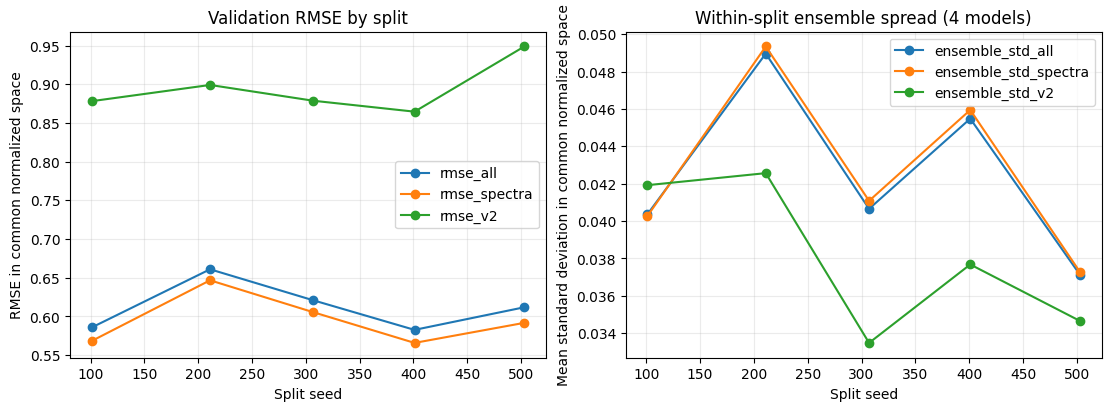

In [28]:
# Split-wise validation diagnostics for the 5 x 4 emulator ensemble
# This cell only evaluates already-trained models; it does not retrain them or rerun MCMC.

split_diagnostic_rows = []
for split_seed in SPLIT_SEEDS:
    split = prepared_splits[split_seed]
    member_predictions_common = []

    for bundle in models_by_split[split_seed]:
        prediction_private_norm = bundle['model'].predict(
            split['Y_valid_norm'], verbose=0
        )
        prediction_transformed = bundle['scalerX'].inverse_transform(
            prediction_private_norm
        )
        member_predictions_common.append(
            scalerX.transform(prediction_transformed)
        )

    member_predictions_common = np.asarray(member_predictions_common)
    prediction_mean = member_predictions_common.mean(axis=0)
    prediction_std = member_predictions_common.std(axis=0, ddof=1)
    validation_truth_common = scalerX.transform(split['X_valid'])
    residual = validation_truth_common - prediction_mean

    rmse_by_bin = np.sqrt(np.mean(np.square(residual), axis=0))
    mean_spread_by_bin = prediction_std.mean(axis=0)
    split_diagnostic_rows.append({
        'split_seed': split_seed,
        'validation_rows': len(split['validation_indices']),
        'rmse_all': float(rmse_by_bin.mean()),
        'rmse_spectra': float(rmse_by_bin[:n_spec].mean()),
        'rmse_v2': float(rmse_by_bin[n_spec:n_obs].mean()),
        'ensemble_std_all': float(mean_spread_by_bin.mean()),
        'ensemble_std_spectra': float(mean_spread_by_bin[:n_spec].mean()),
        'ensemble_std_v2': float(mean_spread_by_bin[n_spec:n_obs].mean()),
    })

split_diagnostics = pd.DataFrame(split_diagnostic_rows).set_index('split_seed')
display(split_diagnostics.round(5))

diagnostic_summary = split_diagnostics.agg(['mean', 'std', 'min', 'max'])
display(diagnostic_summary.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
split_diagnostics[['rmse_all', 'rmse_spectra', 'rmse_v2']].plot(
    marker='o', ax=axes[0]
)
axes[0].set_title('Validation RMSE by split')
axes[0].set_xlabel('Split seed')
axes[0].set_ylabel('RMSE in common normalized space')
axes[0].grid(alpha=0.25)

split_diagnostics[[
    'ensemble_std_all', 'ensemble_std_spectra', 'ensemble_std_v2'
]].plot(marker='o', ax=axes[1])
axes[1].set_title('Within-split ensemble spread (4 models)')
axes[1].set_xlabel('Split seed')
axes[1].set_ylabel('Mean standard deviation in common normalized space')
axes[1].grid(alpha=0.25)
plt.show()
